# YouTube Shorts Virality — EDA

**Question:** What makes a video go viral, and can we predict it early?

Data comes from the `shorts-data` repo (cloned next to this notebook). It has three parts:

| File | One row per | Contents |
|---|---|---|
| `data/channels.csv` | channel | title, creation date, subscribers, total views/videos |
| `data/videos.csv` | video | publish time, channel, title, description, duration, tags |
| `data/observations/*.csv` | video × snapshot | views, likes, comments at a point in time (roughly hourly) |

Run `git pull` inside `shorts-data` to get the newest snapshots before rerunning.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

DATA_DIR = Path("shorts-data") / "data"
assert DATA_DIR.exists(), f"Can't find {DATA_DIR.resolve()} — run this notebook from the Erdos Project folder"


## Load the data

In [2]:
channels = pd.read_csv(DATA_DIR / "channels.csv")
videos = pd.read_csv(DATA_DIR / "videos.csv")
for df, cols in [(channels, ["first_seen_at", "channel_created_at"]), (videos, ["first_seen_at", "published_at"])]:
    for col in cols:
        df[col] = pd.to_datetime(df[col], format="ISO8601", utc=True)

obs_files = sorted((DATA_DIR / "observations").glob("*.csv"))
observations = pd.concat((pd.read_csv(f) for f in obs_files), ignore_index=True)
observations["observed_at"] = pd.to_datetime(observations["observed_at"], format="ISO8601")

print(f"channels:     {channels.shape}")
print(f"videos:       {videos.shape}")
print(f"observations: {observations.shape} from {len(obs_files)} snapshot files")
print(f"snapshots span {observations['observed_at'].min()} → {observations['observed_at'].max()}")


channels:     (4799, 7)
videos:       (6749, 10)
observations: (316303, 6) from 97 snapshot files
snapshots span 2026-10-12 15:37:59.683152+00:00 → 2026-10-16 17:53:37.524519+00:00


In [3]:
channels.head()

,channel_id,first_seen_at,channel_title,channel_created_at,total_channel_views,subscriber_count,total_channel_videos
0,UCJgZiklqrfvvfCDO3QhF1Hg,2026-10-12 15:37:58.074627+00:00,kk shorts video,2021-03-26 15:35:22.996177+00:00,5110271644,3780000,1253
1,UC3NlznSlTlfiNpUhfdJlTiw,2026-10-12 15:37:58.074627+00:00,NLF SoHeL VloG,2024-10-17 06:22:42.920227+00:00,10787169127,3480000,4666
2,UC5k3V8mUODYybpi2O4O6Atw,2026-10-12 15:37:58.074627+00:00,MegaMarkGames,2013-08-02 01:42:13+00:00,9939467,432000,3627
3,UC1PlB1jO4-sfrSdqRrvCllA,2026-10-12 15:37:58.074627+00:00,Ram Ji,2026-06-03 05:24:55.322944+00:00,91083513,95400,269
4,UCTkeM1GjDqx3Bw0q-WVjTNQ,2026-10-12 15:37:58.074627+00:00,小山翔平,2023-02-17 07:46:26.368324+00:00,84502329,78500,3106


In [4]:
videos.head()

,video_id,first_seen_at,published_at,channel_id,channel_title,title,description,duration,duration_seconds,tags
0,L5eQJKakz5U,2026-10-12 15:37:58.074627+00:00,2026-10-12 15:15:22+00:00,UC0cx38VIfmVZva-rYnMmevQ,Amandinha,Abrindo Comprinhas da Shopika 6 #shorts,💜APOIE A AMANDINHA E SE TORNE MEMBRO DO CANAL!...,PT3M,180,[]
1,PdrruRfk_wM,2026-10-12 15:37:58.074627+00:00,2026-10-12 15:10:15+00:00,UCTHuHxhCBITUuP_AchYSstA,RAXON,Who Cleans Spider-Man’s Webs? 🤣😂 | #shorts,Who Cleans Spider-Man’s Webs? 🤣😂 | #shorts\n\n...,PT48S,48,[]
2,LAhmgGBiESw,2026-10-12 15:37:58.074627+00:00,2026-10-12 15:08:05+00:00,UC8_NGoazMiGbRPUTQ52_NdQ,Jagiya the fun,Jagiya ke kurkure aur chota bhai🥲🔥| Indian fam...,Jagiya ke kurkure aur chota bhai🥲🔥| Indian fam...,PT32S,32,[]
3,8qJ5k-vbO3E,2026-10-12 15:37:58.074627+00:00,2026-10-12 15:05:44+00:00,UConRqB3CsY3dAHvVDVsRC4g,Mr_Vlogger,hair loss problem #shorts #minivlog #vlogs,NaN,PT24S,24,[]
4,VP3sxzlp4P0,2026-10-12 15:37:58.074627+00:00,2026-10-12 15:00:07+00:00,UCa9nE9GRjSOXFL1alnROYEA,Rinconcito Animado,¿Dónde se perdió Bob Esponja? 😱 #viral #shorts,🍍😂 ¡Bob Esponja se perdió intentando encontrar...,PT1M2S,62,[]


In [5]:
observations.head()

,video_id,observed_at,age_hours,view_count,like_count,comment_count
0,L5eQJKakz5U,2026-10-12 15:37:59.683152+00:00,0.377,37717,3114.0,238.0
1,PdrruRfk_wM,2026-10-12 15:37:59.683152+00:00,0.462,447,NaN,0.0
2,LAhmgGBiESw,2026-10-12 15:37:59.683152+00:00,0.499,85192,NaN,13.0
3,8qJ5k-vbO3E,2026-10-12 15:37:59.683152+00:00,0.538,104634,923.0,1.0
4,VP3sxzlp4P0,2026-10-12 15:37:59.683152+00:00,0.631,3164,99.0,0.0


## Data quality: types, missing values, duplicates

In [6]:
for name, df in [("channels", channels), ("videos", videos), ("observations", observations)]:
    print(f"--- {name} ---")
    print(df.dtypes.to_string())
    missing = df.isna().mean().mul(100).round(1)
    missing = missing[missing > 0]
    print()
    print("% missing:" if len(missing) else "no missing values")
    if len(missing):
        print(missing.to_string())
    print()


--- channels ---
channel_id                              str
first_seen_at           datetime64[us, UTC]
channel_title                           str
channel_created_at      datetime64[us, UTC]
total_channel_views                   int64
subscriber_count                      int64
total_channel_videos                  int64

no missing values

--- videos ---
video_id                            str
first_seen_at       datetime64[us, UTC]
published_at        datetime64[us, UTC]
channel_id                          str
channel_title                       str
title                               str
description                         str
duration                            str
duration_seconds                  int64
tags                                str

% missing:
description    39.0

--- observations ---
video_id                         str
observed_at      datetime64[us, UTC]
age_hours                    float64
view_count                     int64
like_count                   float64
c

In [7]:
print("duplicate channel_ids:", channels["channel_id"].duplicated().sum())
print("duplicate video_ids:  ", videos["video_id"].duplicated().sum())
print("duplicate (video, snapshot) rows:", observations.duplicated(["video_id", "observed_at"]).sum())
print("observed videos missing from videos.csv:", (~observations["video_id"].isin(videos["video_id"])).sum())


duplicate channel_ids: 0
duplicate video_ids:   0
duplicate (video, snapshot) rows: 0
observed videos missing from videos.csv: 0


## One row per video: latest snapshot

Each video is observed many times. For a first look, keep each video's **most recent** observation and join on video and channel metadata.

In [8]:
latest = (
    observations.sort_values("observed_at")
    .groupby("video_id").tail(1)
    .merge(videos, on="video_id", how="left")
    .merge(channels.drop(columns=["channel_title", "first_seen_at"]), on="channel_id", how="left")
)
n_obs = observations.groupby("video_id").size().rename("n_observations")
latest = latest.merge(n_obs, on="video_id")
print(latest.shape)
latest[["view_count", "like_count", "comment_count", "age_hours", "duration_seconds",
        "subscriber_count", "n_observations"]].describe().T


(6748, 20)


,count,mean,std,min,25%,50%,75%,max
view_count,6748.0,2.578364e+05,8.837763e+05,250.000,25353.250,57043.500,1.796668e+05,2.418603e+07
like_count,5950.0,5.362121e+03,1.968825e+04,0.000,330.000,1002.000,3.634250e+03,7.904810e+05
comment_count,6702.0,1.060404e+02,9.609774e+02,0.000,2.000,8.000,4.200000e+01,6.685600e+04
age_hours,6748.0,4.715601e+01,2.568875e+01,0.337,24.759,48.551,7.387625e+01,7.999800e+01
duration_seconds,6748.0,4.934662e+01,3.645257e+01,4.000,24.000,39.000,6.000000e+01,1.800000e+02
subscriber_count,6748.0,2.527224e+06,7.091449e+06,1.000,60500.000,271000.000,1.370000e+06,8.980000e+07
n_observations,6748.0,4.687359e+01,2.568371e+01,1.000,24.000,48.000,7.300000e+01,8.200000e+01


## First look at the distributions

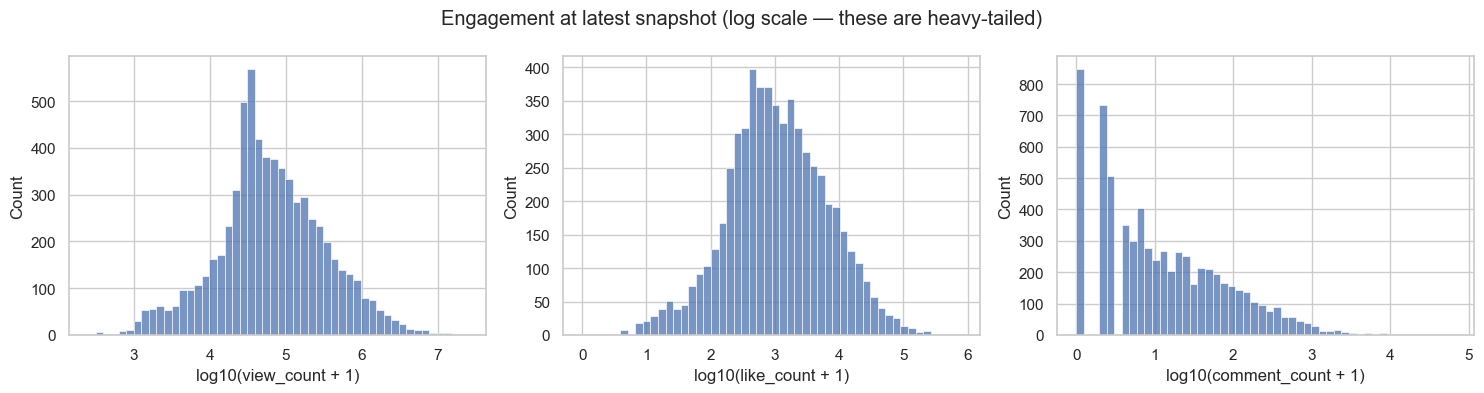

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["view_count", "like_count", "comment_count"]):
    sns.histplot(np.log10(latest[col].dropna() + 1), bins=50, ax=ax)
    ax.set_xlabel(f"log10({col} + 1)")
fig.suptitle("Engagement at latest snapshot (log scale — these are heavy-tailed)")
plt.tight_layout()


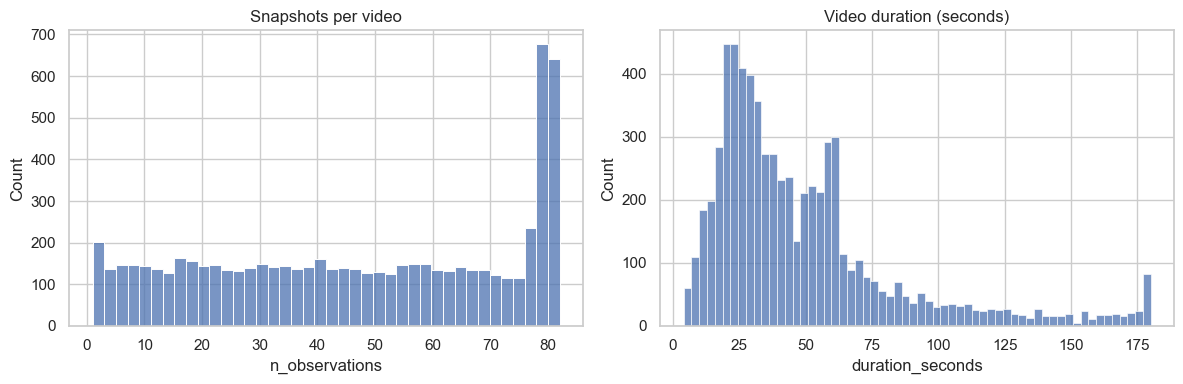

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(latest["n_observations"], bins=40, ax=axes[0])
axes[0].set_title("Snapshots per video")
sns.histplot(latest["duration_seconds"].dropna(), bins=60, ax=axes[1])
axes[1].set_title("Video duration (seconds)")
plt.tight_layout()


## View trajectories

How views grow with video age matters for predicting virality *early*. Plot a random sample of videos.

Text(0.5, 1.0, 'View trajectories for 30 sampled Shorts')

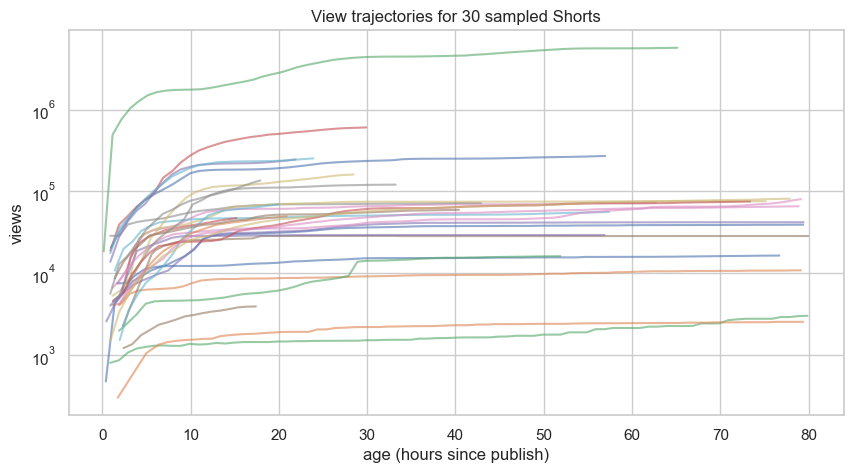

In [11]:
sample_ids = latest.query("n_observations >= 10")["video_id"].sample(30, random_state=0)
fig, ax = plt.subplots(figsize=(10, 5))
for vid, g in observations[observations["video_id"].isin(sample_ids)].groupby("video_id"):
    g = g.sort_values("age_hours")
    ax.plot(g["age_hours"], g["view_count"], alpha=0.6)
ax.set_yscale("log")
ax.set_xlabel("age (hours since publish)")
ax.set_ylabel("views")
ax.set_title("View trajectories for 30 sampled Shorts")


# Part 2: EDA toward the virality question

The sections below build a **one-row-per-video modeling table**: what we know about a video in its first few hours, plus the outcome we want to predict (its views at `TARGET_HOURS`). Then they explore that table along the lines of the checkpoint guide: distributions, missingness, relationships, outliers and lag structure.

Key plots are also saved to `results/eda/`.

In [12]:
import json
from scipy import stats
from statsmodels.tsa.stattools import acf

TARGET_HOURS = 48      # outcome window; switch to 72 once enough videos have aged that far
TARGET_TOL = 2         # accept the snapshot closest to TARGET_HOURS if within ± this many hours
EARLY_HOURS = [1, 3, 6]
EARLY_TOL = 0.75
VIRAL_QUANTILE = 0.90  # "viral" = top 10%

RESULTS_DIR = Path("results") / "eda"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(RESULTS_DIR / f"{name}.png", dpi=120, bbox_inches="tight")

def stats_at(hours, tol):
    # Each video's snapshot closest to `hours` of age, if one exists within `tol` hours.
    o = observations.assign(dist=(observations["age_hours"] - hours).abs()).query("dist <= @tol")
    o = o.sort_values("dist").groupby("video_id").head(1).set_index("video_id")
    return o[["view_count", "like_count", "comment_count"]].add_suffix(f"_{hours}h")

max_age = observations.groupby("video_id")["age_hours"].max()
for h in [6, 24, 48, 72]:
    print(f"videos observed to >= {h}h: {(max_age >= h).sum()}")


videos observed to >= 6h: 6362
videos observed to >= 24h: 5088
videos observed to >= 48h: 3406
videos observed to >= 72h: 1777


## Build the modeling table

Features use only information available in a video's first few hours, or known at upload time, so they're fair to use for *early* prediction. The target columns (`*_{TARGET_HOURS}h`, `viral`, `viral_rel`) must never be used as features.

Two candidate labels:
- `viral`: views at `TARGET_HOURS` in the top 10% of this cohort.
- `viral_rel`: views relative to the channel's average views per video in the top 10%. This asks whether the video beat its own channel's usual performance.

In [13]:
df = (
    videos.set_index("video_id")
    .join([stats_at(h, EARLY_TOL) for h in EARLY_HOURS])
    .join(stats_at(TARGET_HOURS, TARGET_TOL), how="inner")
    .reset_index()
    .merge(channels.drop(columns=["channel_title", "first_seen_at"]), on="channel_id", how="left")
)
target = f"view_count_{TARGET_HOURS}h"

# Upload-time features
df["pub_hour_utc"] = df["published_at"].dt.hour
df["pub_dow"] = df["published_at"].dt.day_name().str[:3]
df["title_len"] = df["title"].fillna("").str.len()
df["n_hashtags"] = df["title"].fillna("").str.count("#") + df["description"].fillna("").str.count("#")
df["n_tags"] = df["tags"].fillna("[]").apply(lambda s: len(json.loads(s)))
df["has_description"] = df["description"].notna()
df["ascii_title"] = df["title"].fillna("").apply(str.isascii)  # rough proxy for English vs non-English

# Channel features (channel stats are as of first sighting, so known early)
df["channel_age_days"] = (df["published_at"] - df["channel_created_at"]).dt.days
df["channel_avg_views"] = df["total_channel_views"] / df["total_channel_videos"].clip(lower=1)

# Early-engagement features
df["likes_hidden"] = df["like_count_6h"].isna() & df["view_count_6h"].notna()
df["like_rate_6h"] = df["like_count_6h"] / df["view_count_6h"].replace(0, np.nan)
df["comment_rate_6h"] = df["comment_count_6h"] / df["view_count_6h"].replace(0, np.nan)
df["growth_1h_to_6h"] = df["view_count_6h"] / df["view_count_1h"].replace(0, np.nan)

# Labels
df["viral"] = df[target] >= df[target].quantile(VIRAL_QUANTILE)
df["rel_views"] = df[target] / df["channel_avg_views"].replace(0, np.nan)
df["viral_rel"] = df["rel_views"] >= df["rel_views"].quantile(VIRAL_QUANTILE)

print(f"{len(df)} videos with a {TARGET_HOURS}h outcome")
print(f"viral threshold: {df[target].quantile(VIRAL_QUANTILE):,.0f} views (median {df[target].median():,.0f})")


3530 videos with a 48h outcome
viral threshold: 620,041 views (median 66,808)


## Missingness

How many values are missing in each column of the modeling table, and what percent of rows that is.

In [14]:
feature_cols = ["view_count_1h", "view_count_3h", "view_count_6h", "like_count_6h", "comment_count_6h",
                "description", "subscriber_count", "duration_seconds", "title_len"]

missing = pd.DataFrame({
    "missing": df[feature_cols].isna().sum(),
    "percent": df[feature_cols].isna().mean().mul(100).round(1),
}).sort_values("missing", ascending=False)

print(f"{len(df)} videos in the modeling table")
missing

3530 videos in the modeling table


,missing,percent
description,1370,38.8
view_count_1h,822,23.3
like_count_6h,484,13.7
view_count_3h,118,3.3
comment_count_6h,99,2.8
view_count_6h,79,2.2
subscriber_count,0,0.0
duration_seconds,0,0.0
title_len,0,0.0


## Box plots: outcome by group

Log scale throughout, since views span several orders of magnitude. Publish hour is in **UTC**. Creators are worldwide, so it isn't their local time.

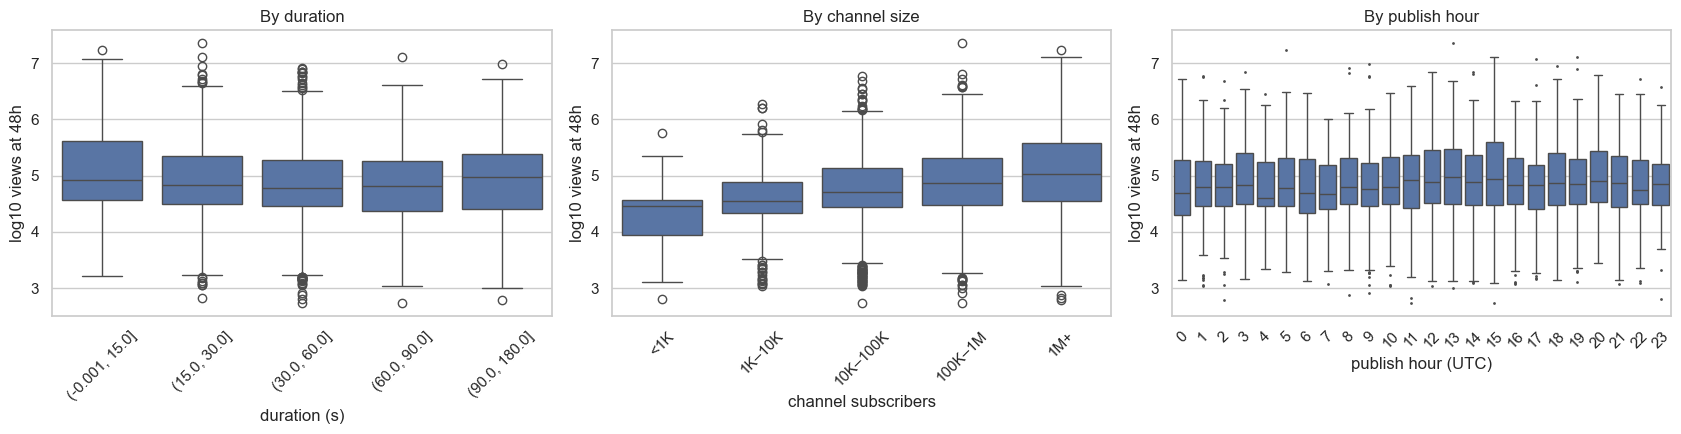

In [15]:
df["log_target"] = np.log10(df[target] + 1)
df["duration_bin"] = pd.cut(df["duration_seconds"], [0, 15, 30, 60, 90, 180], include_lowest=True)
df["subs_bin"] = pd.cut(df["subscriber_count"], [-1, 1e3, 1e4, 1e5, 1e6, np.inf],
                        labels=["<1K", "1K–10K", "10K–100K", "100K–1M", "1M+"])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=df, x="duration_bin", y="log_target", ax=axes[0])
axes[0].set(xlabel="duration (s)", title="By duration")
sns.boxplot(data=df, x="subs_bin", y="log_target", ax=axes[1])
axes[1].set(xlabel="channel subscribers", title="By channel size")
sns.boxplot(data=df, x="pub_hour_utc", y="log_target", ax=axes[2], fliersize=1)
axes[2].set(xlabel="publish hour (UTC)", title="By publish hour")
for ax in axes:
    ax.set_ylabel(f"log10 views at {TARGET_HOURS}h")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
save(fig, "boxplots_by_group")


## Correlation heatmap

Spearman (rank) correlation, which is robust to the heavy tails. Look at two things: which features track the target, and which features are near-duplicates of each other (redundancy, per the feature-selection step).

view_count_6h           0.868
view_count_3h           0.776
view_count_1h           0.720
channel_avg_views       0.590
growth_1h_to_6h         0.430
subscriber_count        0.206
total_channel_videos   -0.131
like_rate_6h            0.127
n_tags                 -0.111
channel_age_days       -0.102
pub_hour_utc            0.051
duration_seconds       -0.043
comment_rate_6h         0.031
title_len               0.024
n_hashtags             -0.006
Name: view_count_48h, dtype: float64

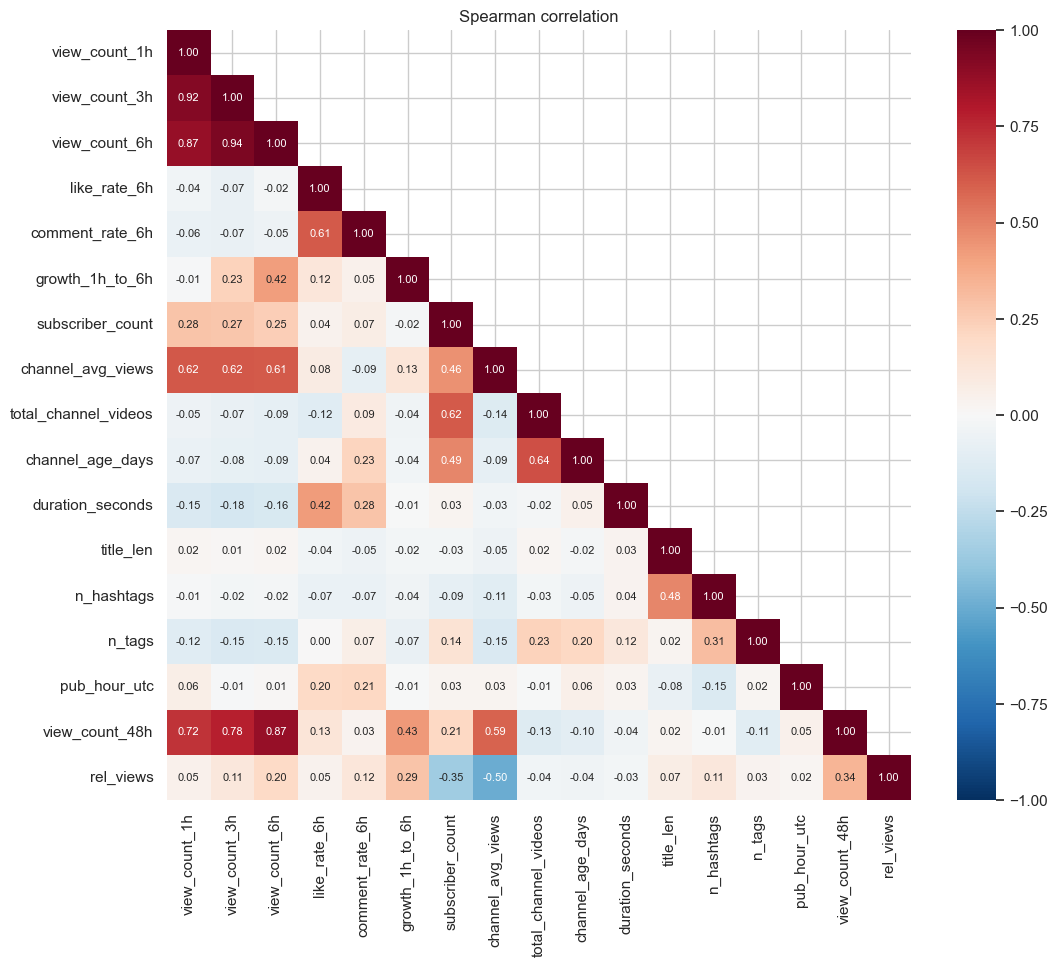

In [16]:
corr_cols = ["view_count_1h", "view_count_3h", "view_count_6h", "like_rate_6h", "comment_rate_6h",
             "growth_1h_to_6h", "subscriber_count", "channel_avg_views", "total_channel_videos",
             "channel_age_days", "duration_seconds", "title_len", "n_hashtags", "n_tags",
             "pub_hour_utc", target, "rel_views"]
corr = df[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 8}, ax=ax)
ax.set_title("Spearman correlation")
save(fig, "correlation_heatmap")

corr[target].drop([target, "rel_views"]).sort_values(key=abs, ascending=False).round(3)


## How well do early views predict the outcome?

This is the core of "can we predict it early?" Each panel plots views at hour N against views at the target age.

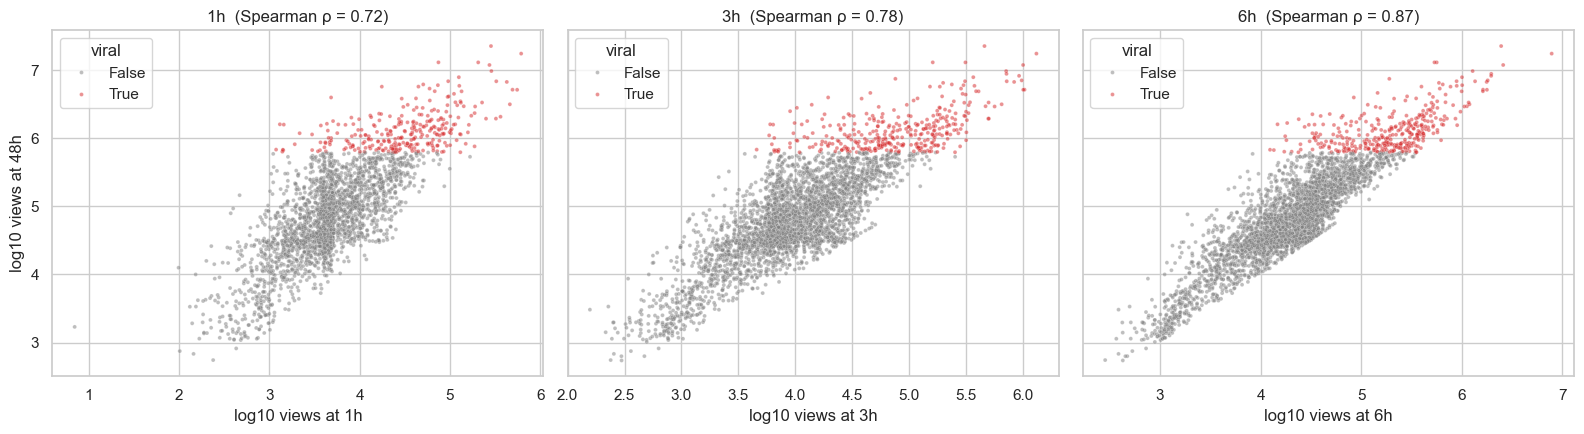

In [17]:
fig, axes = plt.subplots(1, len(EARLY_HOURS), figsize=(16, 4.5), sharey=True)
for ax, h in zip(axes, EARLY_HOURS):
    d = df.dropna(subset=[f"view_count_{h}h"])
    sns.scatterplot(x=np.log10(d[f"view_count_{h}h"] + 1), y=d["log_target"], hue=d["viral"],
                    s=8, alpha=0.5, ax=ax, palette={False: "tab:gray", True: "tab:red"})
    rho = d[f"view_count_{h}h"].corr(d[target], method="spearman")
    ax.set(xlabel=f"log10 views at {h}h", ylabel=f"log10 views at {TARGET_HOURS}h", title=f"{h}h  (Spearman ρ = {rho:.2f})")
plt.tight_layout()
save(fig, "early_vs_target_views")


## Growth curves: viral vs. non-viral

Median views by age, with the interquartile range shaded. Where the two bands separate is roughly how early the signal appears.

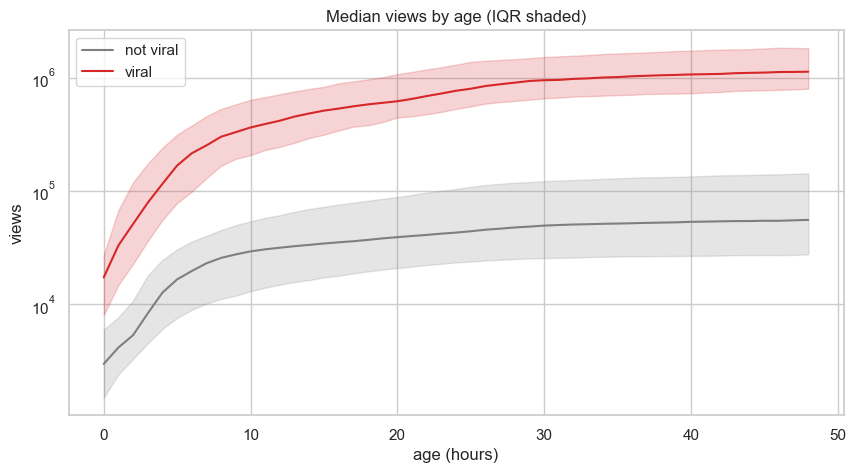

In [18]:
curves = observations.merge(df[["video_id", "viral"]], on="video_id")
curves["age_bin"] = curves["age_hours"].round()
curves = curves[curves["age_bin"] <= TARGET_HOURS]
summary = curves.groupby(["viral", "age_bin"])["view_count"].quantile([0.25, 0.5, 0.75]).unstack()

fig, ax = plt.subplots(figsize=(10, 5))
for is_viral, color in [(False, "tab:gray"), (True, "tab:red")]:
    s = summary.loc[is_viral]
    ax.plot(s.index, s[0.5], color=color, label="viral" if is_viral else "not viral")
    ax.fill_between(s.index, s[0.25], s[0.75], color=color, alpha=0.2)
ax.set(yscale="log", xlabel="age (hours)", ylabel="views", title="Median views by age (IQR shaded)")
ax.legend()
save(fig, "growth_curves_viral_vs_not")


## Two definitions of viral: how much do they agree?

In [19]:
print(pd.crosstab(df["viral"], df["viral_rel"], margins=True))
both = (df["viral"] & df["viral_rel"]).sum()
print(f"\nJaccard overlap: {both / (df['viral'] | df['viral_rel']).sum():.2f}")
print("\nmedian subscribers by label:")
print(df.groupby(["viral", "viral_rel"])["subscriber_count"].median().map("{:,.0f}".format))


viral_rel  False  True   All
viral                       
False       2896   281  3177
True         281    72   353
All         3177   353  3530

Jaccard overlap: 0.11

median subscribers by label:
viral  viral_rel
False  False          276,000
       True            53,300
True   False        1,430,000
       True           197,000
Name: subscriber_count, dtype: str


## Outliers and data quality

- **Z-scores** on log views flag extreme videos.
- **Isolation Forest** flags unusual combinations of features, not just extreme values in one feature.
- **View counts that go down** between snapshots: YouTube sometimes removes invalid views, so counts aren't strictly increasing.

In [20]:
from sklearn.ensemble import IsolationForest

df["target_z"] = stats.zscore(df["log_target"])
print(f"|z| > 3 on log views: {(df['target_z'].abs() > 3).sum()} videos")

iso_cols = ["view_count_6h", "subscriber_count", "channel_avg_views", "duration_seconds"]
iso_X = np.log10(df[iso_cols].dropna() + 1)
df["iso_outlier"] = False
df.loc[iso_X.index, "iso_outlier"] = IsolationForest(contamination=0.02, random_state=0).fit_predict(iso_X) == -1
print(f"IsolationForest outliers: {df['iso_outlier'].sum()} videos")
display(df.loc[df["iso_outlier"], ["title", "channel_title", "subscriber_count", "view_count_6h", target]].head(10))

o = observations.sort_values(["video_id", "observed_at"])
drops = o.groupby("video_id")["view_count"].diff()
print(f"\nsnapshots where views went down: {(drops < 0).sum()} across {o.loc[drops < 0, 'video_id'].nunique()} videos")
print("size of drop as a fraction of views:")
print((drops[drops < 0] / o.loc[drops < 0, "view_count"]).describe().round(4))


|z| > 3 on log views: 8 videos
IsolationForest outliers: 69 videos


,title,channel_title,subscriber_count,view_count_6h,view_count_48h
0,Abrindo Comprinhas da Shopika 6 #shorts,Amandinha,12100000,321493.0,1140414
12,శాలిని vs వర్షిణి 🔥 #shorts #biggboss #shalini...,AIR - UPSC | APPSC | TGPSC,323,138446.0,575563
119,ЧУКЧА! 😂 #shorts #юмор #анекдоты,ЮМОР от ПИСТОНЫЧА,665,30887.0,63442
120,Navratri Day 2 Garba 💃🔥 | Gujarati Garba Night...,RealRush,85,5438.0,67079
317,Invincible#invincible #shorts,AQI,8,1244.0,1271
399,Scary Office Halloween Decorations: Workplace ...,New Country 105.1 KNCI,2190,1130.0,1175
407,Zach D films edit. #funny #...,Animator,132,7490.0,7765
492,West Virginia's Fight for Freedom: Slavery's E...,Truth & Liberty,26300,584.0,1415
495,Elon Musk Is a Trillionaire💰.#elonmusk #trilli...,The Net Worth Lab,1,1284.0,1470
555,Twitch QUADRA KILL | NA Master Patch 26.20 #sh...,Twitch Challenger Replays,426,472.0,630



snapshots where views went down: 6241 across 1916 videos
size of drop as a fraction of views:
count    6241.0000
mean       -0.0027
std         0.0182
min        -1.0769
25%        -0.0016
50%        -0.0005
75%        -0.0001
max        -0.0000
Name: view_count, dtype: float64


## Lag structure: view velocity over time

Velocity = new views per hour between consecutive snapshots. If velocity is strongly autocorrelated, a video's recent pace is a good guide to its next few hours, which is what makes early prediction plausible.

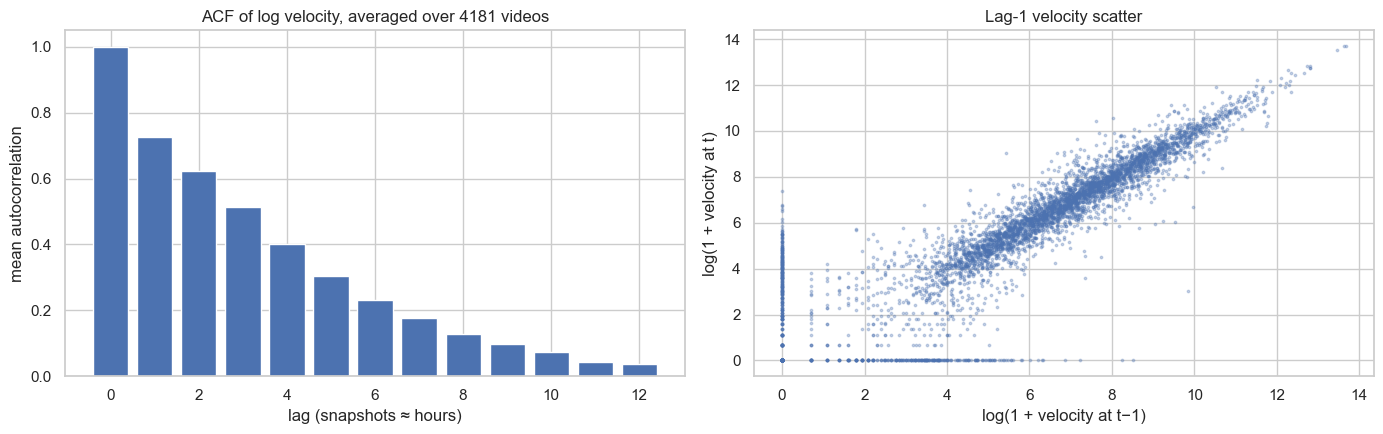

In [21]:
o = observations.sort_values(["video_id", "age_hours"]).copy()
o["velocity"] = (o.groupby("video_id")["view_count"].diff() / o.groupby("video_id")["age_hours"].diff()).clip(lower=0)
o["velocity_lag1"] = o.groupby("video_id")["velocity"].shift()

# Average the per-video ACF over videos with long histories
long_ids = o.groupby("video_id")["velocity"].count().loc[lambda s: s >= 36].index
acfs = np.array([acf(np.log1p(g["velocity"].dropna()), nlags=12)
                 for _, g in o[o["video_id"].isin(long_ids)].groupby("video_id")])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(range(13), np.nanmean(acfs, axis=0))
axes[0].set(xlabel="lag (snapshots ≈ hours)", ylabel="mean autocorrelation",
            title=f"ACF of log velocity, averaged over {len(acfs)} videos")
sample = o.dropna(subset=["velocity", "velocity_lag1"]).sample(5000, random_state=0)
axes[1].scatter(np.log1p(sample["velocity_lag1"]), np.log1p(sample["velocity"]), s=3, alpha=0.3)
axes[1].set(xlabel="log(1 + velocity at t−1)", ylabel="log(1 + velocity at t)", title="Lag-1 velocity scatter")
plt.tight_layout()
save(fig, "velocity_acf")
